In [ ]:
import pandas as pd
import seaborn as sns
import re
import matplotlib.pyplot as plt
from ipywidgets import Dropdown, FloatSlider, IntSlider, interact
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge  # noqa F401
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline

In [ ]:
from datasets import load_dataset

ds = load_dataset("mo-hug-me/used-car-listings-dataset-from-hatla2ee2026")

In [ ]:

# Combine all splits into one DataFrame
df = pd.concat(
    [dfs.to_pandas() for dfs in ds.values()],
    ignore_index=True
)

In [ ]:
def plot_cardinality(df, column_name, figsize=(20, 6), color='coral'):
    plt.figure(figsize=figsize)

    df[column_name].value_counts().plot(kind='barh', color=color)

    plt.title(f'Cardinality of "{column_name}" = {df[column_name].nunique()}')
    plt.xlabel('Count')
    plt.tight_layout()
    plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22429 entries, 0 to 22428
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         22429 non-null  object 
 1   model         22429 non-null  object 
 2   year          22428 non-null  float64
 3   km            22429 non-null  object 
 4   fuel          22244 non-null  object 
 5   transmission  22429 non-null  object 
 6   price         19503 non-null  object 
 7   description   22429 non-null  object 
dtypes: float64(1), object(7)
memory usage: 1.4+ MB


In [ ]:
df.head(-1)

,brand,model,year,km,fuel,transmission,price,description
0,Kia,Rio,2013.0,"122,000 KM",Gas,Automatic,"530,000 EGP",Kia Rio 2013
1,Chevrolet,Aveo,2017.0,"2,017 KM",Gas,Automatic,"395,000 EGP",Chevrolet Aveo 2017
2,Hyundai,Matrix,2006.0,"260,000 KM",Diesel,Automatic,"410,000 EGP",Hyundai Matrix 2006
3,Nissan,Qashqai,2025.0,"50,000 KM",Gas,Automatic,"1,320,000 EGP",Nissan Qashqai 2025
4,Daewoo,Lanos 2,2006.0,"260,000 KM",Gas,Manual,"255,000 EGP",Daewoo Lanos 2 2006
...,...,...,...,...,...,...,...,...
22423,Nissan,Sunny,2007.0,"177,000 KM",Gas,Automatic,None,Nissan Sunny 2007
22424,Hyundai,Tucson Turbo GDI,2025.0,"11,000 KM",Gas,Automatic,None,Hyundai Tucson Turbo GDI 2025
22425,Renault,Duster,2021.0,0 KM,Gas,Automatic,None,Renault Duster 2021
22426,Skoda,Octavia A8,2021.0,"70,000 KM",Gas,Automatic,None,Skoda Octavia A8 2021


In [ ]:
check = df["brand"] + " " + df["model"] + " " + df["year"].astype("Int64").astype(str)
print((check == df["description"]).mean())   # 1.0 → fully redundant
df[check != df["description"]]               # inspect mismatches, they may hold extra info

0.9962548486334656


,brand,model,year,km,fuel,transmission,price,description
116,Peugeot,2008,2016.0,"183,000 KM",Gas,Automatic,"450,000 EGP",Peugeot 2008
502,Lada,2017,2007.0,0 KM,Gas,Manual,"125,000 EGP",Lada 2017
527,Peugeot,2008,2022.0,"119,000 KM",Gas,Automatic,"1,075,000 EGP",Peugeot 2008
603,Aston,Martin DB9 Volante,2020.0,"20,000 KM",Natural Gas,Manual,"11,000,000 EGP",Aston Martin DB9 Volante 2020
751,Lada,2017,2010.0,"290,000 KM",Natural Gas,Manual,"140,000 EGP",Lada 2017
...,...,...,...,...,...,...,...,...
20619,Peugeot,2008,2021.0,"112,000 KM",Gas,Automatic,None,Peugeot 2008
20700,Peugeot,2008,2015.0,"190,000 KM",Gas,Automatic,None,Peugeot 2008
21258,Peugeot,2008,2024.0,0 KM,Gas,Automatic,None,Peugeot 2008
21830,Peugeot,2008,2022.0,"50,000 KM",Gas,Automatic,None,Peugeot 2008


In [ ]:
df.drop(columns="description" , inplace=True)

In [ ]:
df = df.dropna(subset=["price"])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19503 entries, 0 to 19502
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         19503 non-null  object 
 1   model         19503 non-null  object 
 2   year          19502 non-null  float64
 3   km            19503 non-null  object 
 4   fuel          19349 non-null  object 
 5   transmission  19503 non-null  object 
 6   price         19503 non-null  object 
dtypes: float64(1), object(6)
memory usage: 1.2+ MB


In [ ]:
df.head()

,brand,model,year,km,fuel,transmission,price
0,Kia,Rio,2013.0,"122,000 KM",Gas,Automatic,"530,000 EGP"
1,Chevrolet,Aveo,2017.0,"2,017 KM",Gas,Automatic,"395,000 EGP"
2,Hyundai,Matrix,2006.0,"260,000 KM",Diesel,Automatic,"410,000 EGP"
3,Nissan,Qashqai,2025.0,"50,000 KM",Gas,Automatic,"1,320,000 EGP"
4,Daewoo,Lanos 2,2006.0,"260,000 KM",Gas,Manual,"255,000 EGP"


In [ ]:
df['fuel'].value_counts()

,count
fuel,
Gas,17800
Diesel,671
Natural Gas,364
Electric,307
Hybrid,207


In [ ]:
df['fuel'] = df['fuel'].fillna(df['fuel'].mode()[0])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19503 entries, 0 to 19502
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         19503 non-null  object 
 1   model         19503 non-null  object 
 2   year          19502 non-null  float64
 3   km            19503 non-null  object 
 4   fuel          19503 non-null  object 
 5   transmission  19503 non-null  object 
 6   price         19503 non-null  object 
dtypes: float64(1), object(6)
memory usage: 1.2+ MB


In [ ]:
df = df.dropna(subset=["year"])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19502 entries, 0 to 19502
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         19502 non-null  object 
 1   model         19502 non-null  object 
 2   year          19502 non-null  float64
 3   km            19502 non-null  object 
 4   fuel          19502 non-null  object 
 5   transmission  19502 non-null  object 
 6   price         19502 non-null  object 
dtypes: float64(1), object(6)
memory usage: 1.2+ MB


In [ ]:
df["price"] = df["price"].str.replace(r"[^\d]", "", regex=True).astype(float)
df["km"]    = df["km"].str.replace(r"[^\d]", "", regex=True).astype(float)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19502 entries, 0 to 19502
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         19502 non-null  object 
 1   model         19502 non-null  object 
 2   year          19502 non-null  float64
 3   km            19502 non-null  float64
 4   fuel          19502 non-null  object 
 5   transmission  19502 non-null  object 
 6   price         19502 non-null  float64
dtypes: float64(3), object(4)
memory usage: 1.2+ MB


In [ ]:
df.head()

,brand,model,year,km,fuel,transmission,price
0,Kia,Rio,2013.0,122000.0,Gas,Automatic,530000.0
1,Chevrolet,Aveo,2017.0,2017.0,Gas,Automatic,395000.0
2,Hyundai,Matrix,2006.0,260000.0,Diesel,Automatic,410000.0
3,Nissan,Qashqai,2025.0,50000.0,Gas,Automatic,1320000.0
4,Daewoo,Lanos 2,2006.0,260000.0,Gas,Manual,255000.0


In [ ]:
df["car_age"] = 2026 - df["year"]
df.drop(columns="year" , inplace=True)

In [ ]:
df.head()

,brand,model,km,fuel,transmission,price,car_age
0,Kia,Rio,122000.0,Gas,Automatic,530000.0,13.0
1,Chevrolet,Aveo,2017.0,Gas,Automatic,395000.0,9.0
2,Hyundai,Matrix,260000.0,Diesel,Automatic,410000.0,20.0
3,Nissan,Qashqai,50000.0,Gas,Automatic,1320000.0,1.0
4,Daewoo,Lanos 2,260000.0,Gas,Manual,255000.0,20.0


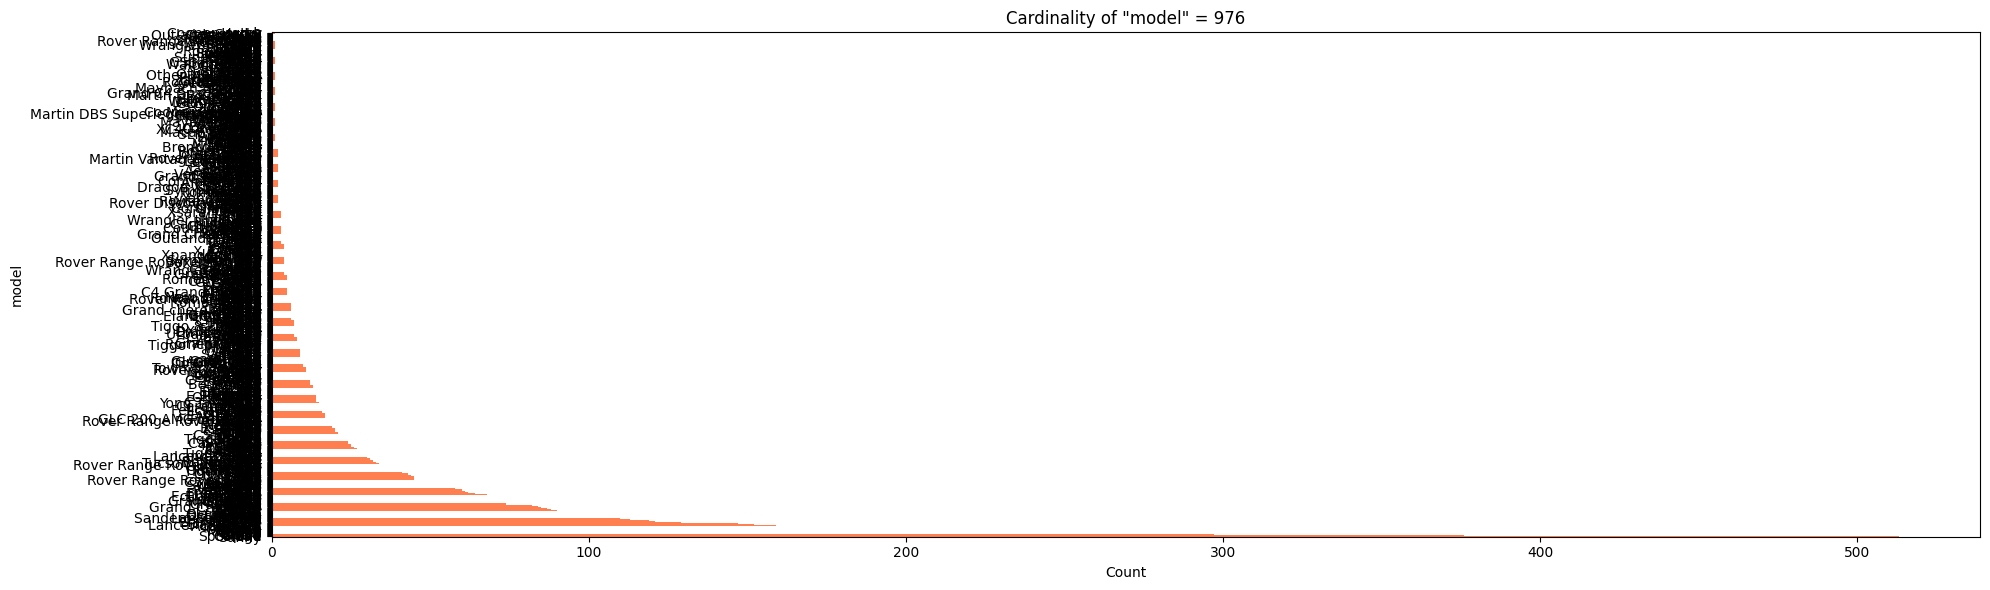

In [ ]:
plot_cardinality(df, 'model')

In [ ]:
df["brand_model"] = df["brand"] + " " + df["model"]
df.drop(columns="model" , inplace=True)

In [ ]:
df.head()

,brand,km,fuel,transmission,price,car_age,brand_model
0,Kia,122000.0,Gas,Automatic,530000.0,13.0,Kia Rio
1,Chevrolet,2017.0,Gas,Automatic,395000.0,9.0,Chevrolet Aveo
2,Hyundai,260000.0,Diesel,Automatic,410000.0,20.0,Hyundai Matrix
3,Nissan,50000.0,Gas,Automatic,1320000.0,1.0,Nissan Qashqai
4,Daewoo,260000.0,Gas,Manual,255000.0,20.0,Daewoo Lanos 2


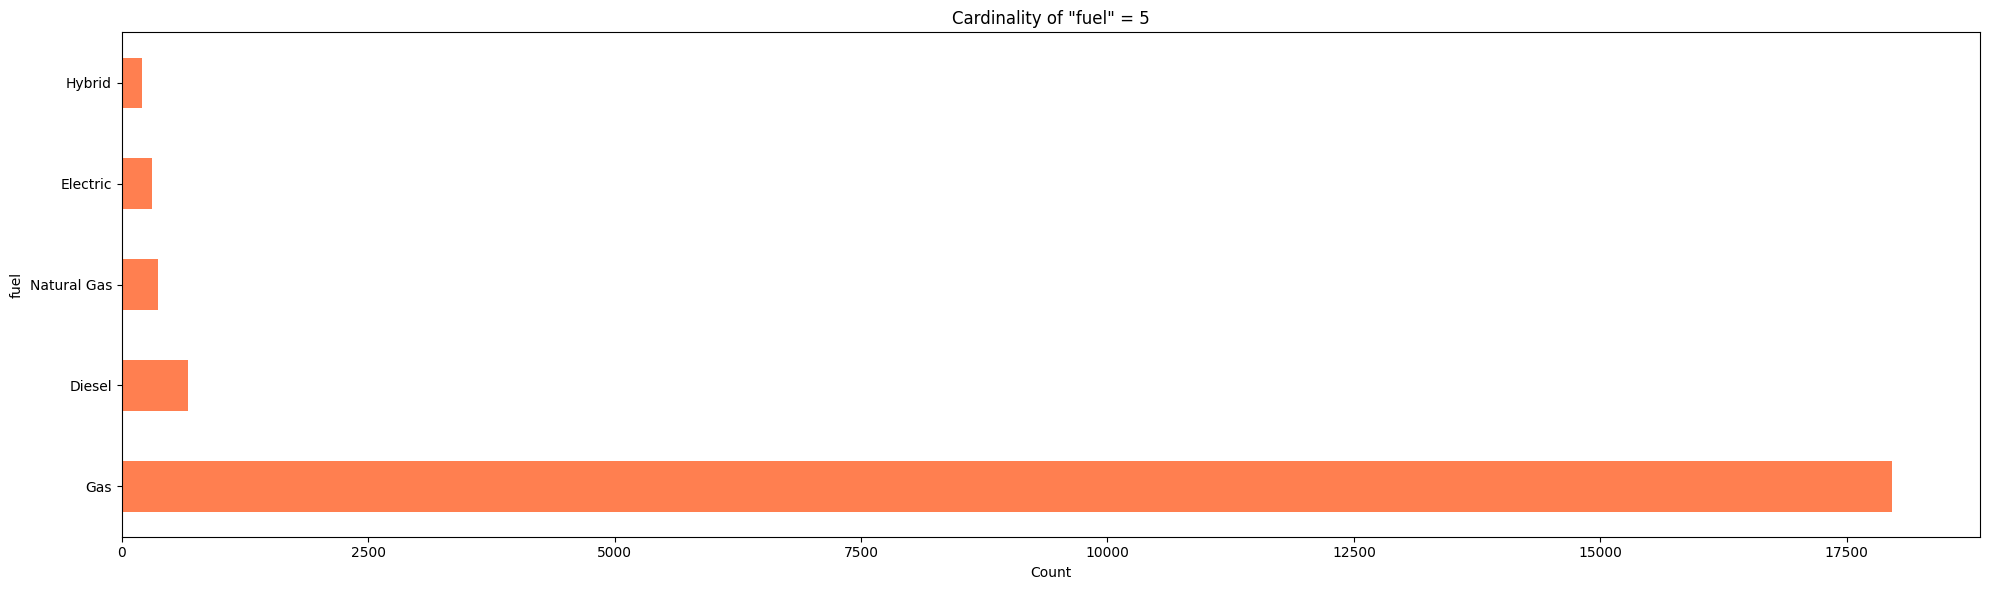

In [ ]:
plot_cardinality(df, 'fuel')

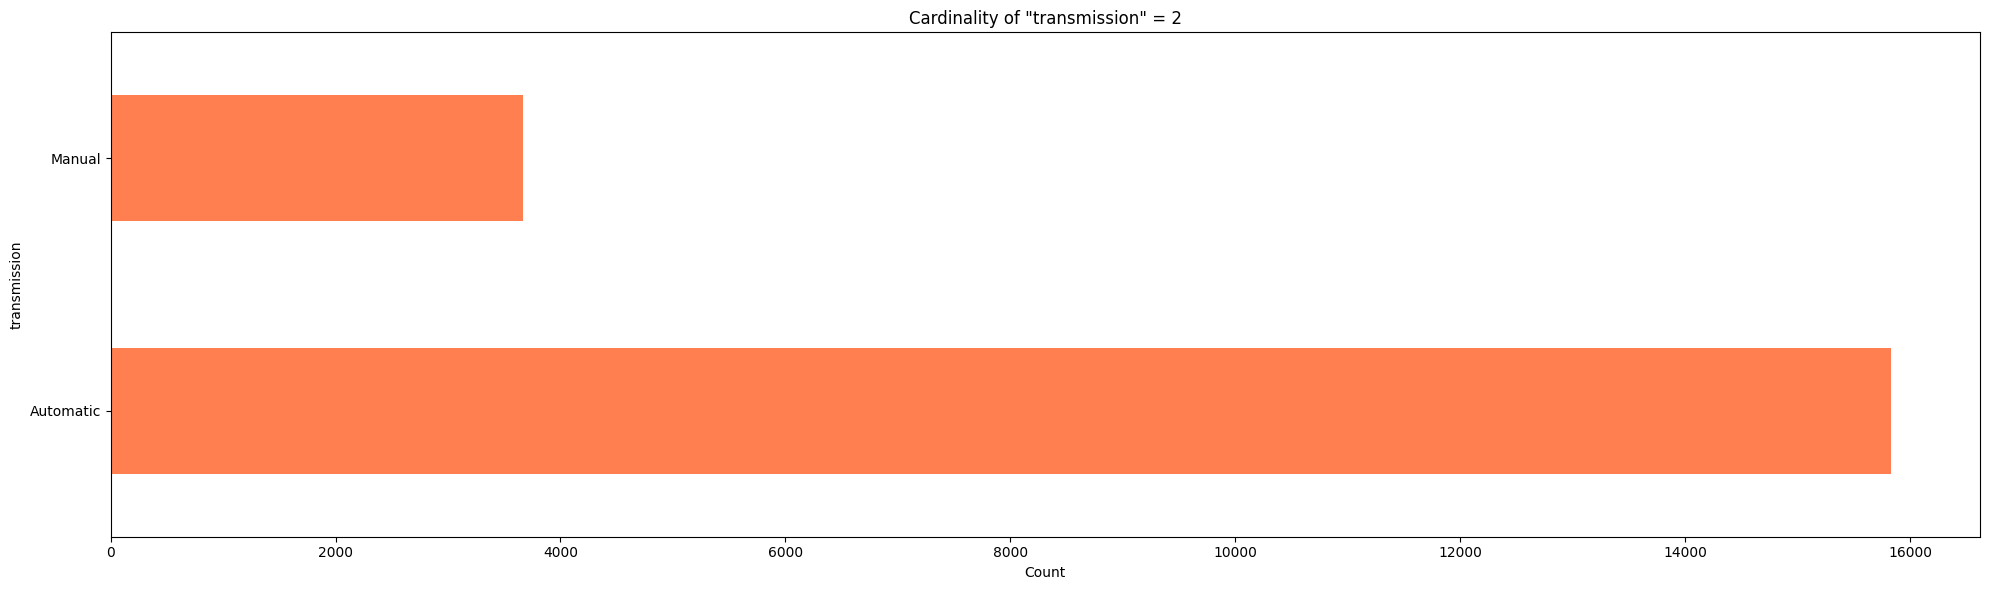

In [ ]:
plot_cardinality(df, 'transmission')

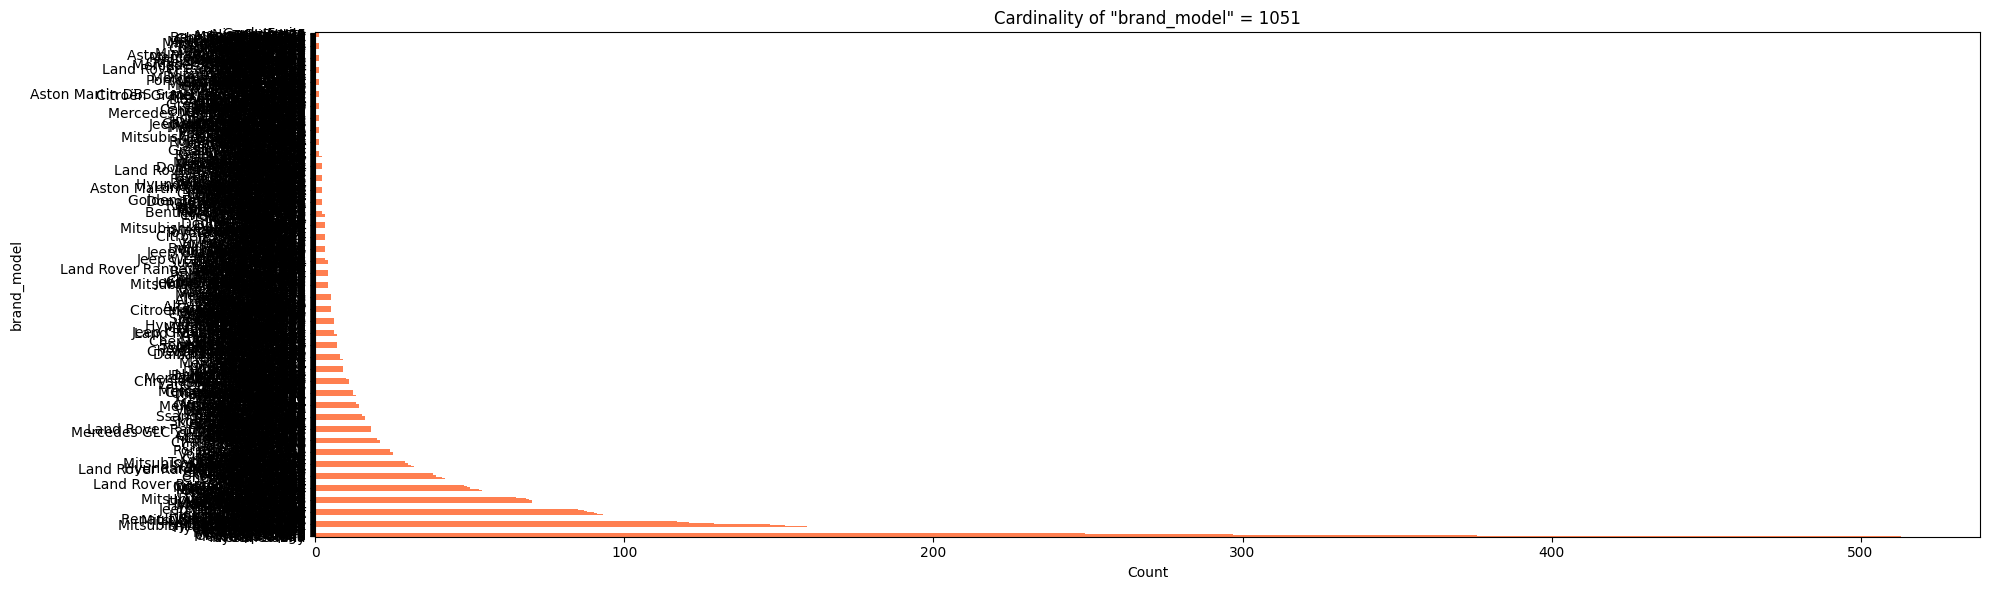

In [ ]:
plot_cardinality(df, 'brand_model')

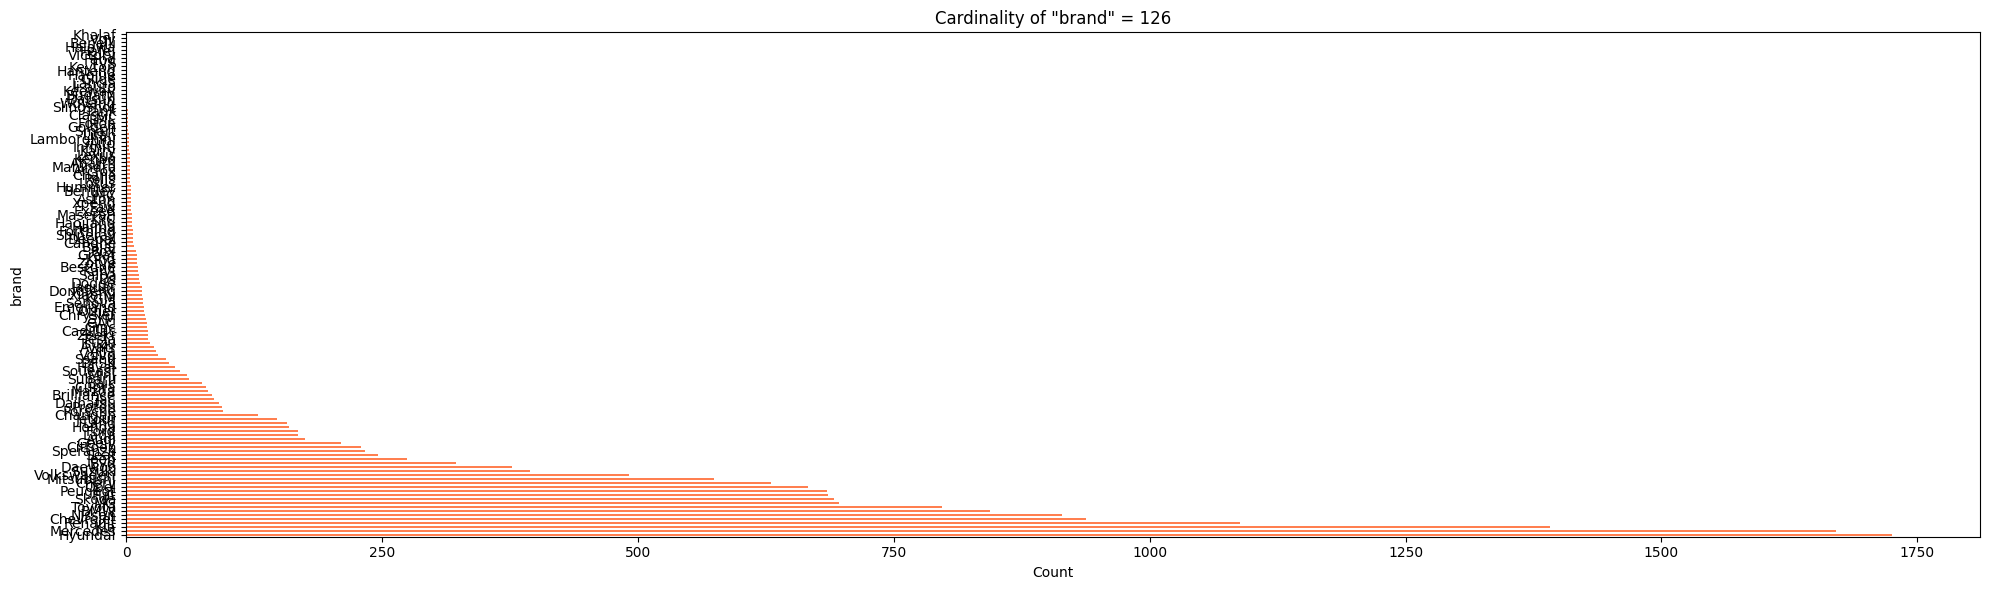

In [ ]:
plot_cardinality(df, 'brand')